My goal in to compare data and word counts between the Iliad and the Odyessy to provide some evidence for (or against) the shared authorship of homer. To acheive this, I will either compare translated word counts or the original word counts. My hypothesis is that a given author prefers to use certain words more often than others and this will create something similar to a signature. If that signature can be compared to another work and matches, then there is a stronger likelihood that both works share an author.

<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Ethan\AppData\Local\Temp\ipykernel_29956\4180717036.py:35: SyntaxWa

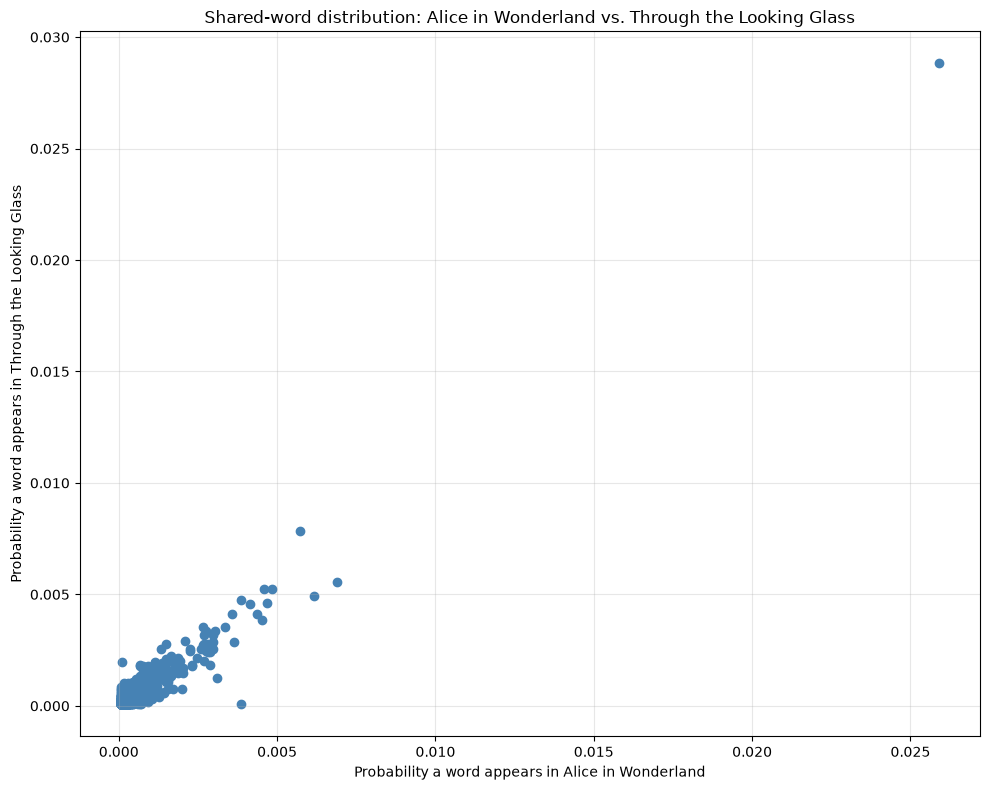

In [45]:
import requests, re
# re is a module for regular expressions: to detect various combinations of characters
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

# we may not care about the usage of stop words
try:
    stop_words = nltk.corpus.stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = nltk.corpus.stopwords.words("english")

stop_words += [
    "ut", "'re", ".", ",", "--", "'s", "?", ")", "(", ":", "'",
    '"', "-", "}", "{", "&", "|", "\u2014"
]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs), 10000)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists    
(wf_ee, tw_ee) = get_wf('http://www.gutenberg.org/ebooks/12.txt.utf-8') # Through the Looking Glass
(wf_bu, tw_bu) = get_wf('http://www.gutenberg.org/ebooks/11.txt.utf-8') # Alice in Wonderland



# Plot the distribution of each word in each text, compared with the general English distribution

try:
    import wordfreq
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wordfreq"], stdout=subprocess.DEVNULL)
    import wordfreq


def normalize_counter(counter):
    if isinstance(counter, list):
        counter = dict(counter)
    total = sum(counter.values())
    if total == 0:
        return {}
    return {word: count / total for word, count in counter.items()}

# Convert the top-word lists into distributions and remove names/proper nouns.
name_words = {
    "alice", "wonderland", "white", "rabbit", "queen", "queenie", "lily",
    "dormouse", "duchess", "caterpillar", "hatter", "hare", "mouse",
    "mock", "turtle", "gryphon", "tweedledee", "tweedledum", "king",
    "princess", "knave", "march", "through", "looking", "glass"
}

wf_ee_dist = {
    w: p for w, p in normalize_counter(dict(wf_ee)).items()
    if w not in name_words and w.isalpha() and w[0].islower()
}
wf_bu_dist = {
    w: p for w, p in normalize_counter(dict(wf_bu)).items()
    if w not in name_words and w.isalpha() and w[0].islower()
}

# General English reference built from the same vocabulary, then normalized.
all_words = set(wf_ee_dist) | set(wf_bu_dist)
english_ref = {word: 10 ** (wordfreq.zipf_frequency(word, "en") - 1) for word in all_words}
english_total = sum(english_ref.values())
english_dist = {word: freq / english_total for word, freq in english_ref.items()}

# Scatter plot: Odyssey probability on x-axis, Iliad probability on y-axis.
# Each point is one shared word.
words = sorted(set(wf_ee_dist) & set(wf_bu_dist))

x_vals = [wf_ee_dist[w] for w in words]
y_vals = [wf_bu_dist[w] for w in words]

plt.figure(figsize=(10, 8))
plt.scatter(x_vals, y_vals, alpha=1, color='steelblue')

plt.xlabel('Probability a word appears in Alice in Wonderland')
plt.ylabel('Probability a word appears in Through the Looking Glass')
plt.title('Shared-word distribution: Alice in Wonderland vs. Through the Looking Glass')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Ethan\AppData\Local\Temp\ipykernel_29956\168689586.py:35: SyntaxWar

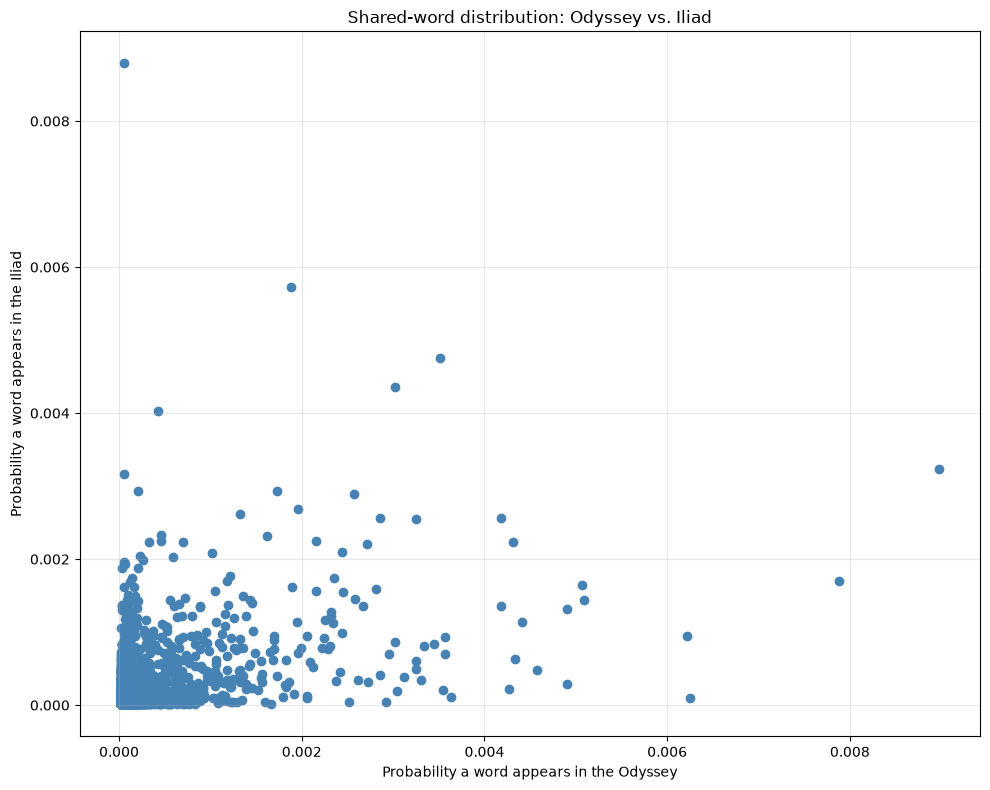

In [46]:
import requests, re
# re is a module for regular expressions: to detect various combinations of characters
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

# we may not care about the usage of stop words
try:
    stop_words = nltk.corpus.stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = nltk.corpus.stopwords.words("english")

stop_words += [
    "ut", "'re", ".", ",", "--", "'s", "?", ")", "(", ":", "'",
    '"', "-", "}", "{", "&", "|", "\u2014"
]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs), 10000)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists    
(wf_ee, tw_ee) = get_wf('http://www.gutenberg.org/ebooks/1727.txt.utf-8') # Odyessy
(wf_bu, tw_bu) = get_wf('http://www.gutenberg.org/ebooks/6130.txt.utf-8') # Iliad



# Plot the distribution of each word in each text, compared with the general English distribution

try:
    import wordfreq
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wordfreq"], stdout=subprocess.DEVNULL)
    import wordfreq


def normalize_counter(counter):
    if isinstance(counter, list):
        counter = dict(counter)
    total = sum(counter.values())
    if total == 0:
        return {}
    return {word: count / total for word, count in counter.items()}

# Convert the top-word lists into distributions and remove names/proper nouns.
name_words = {
    "odysseus", "telemachus", "penelope", "athena", "odyssey", "iliad", "homer",
    "achilles", "helen", "agamemnon", "ulysses", "trojan", "troy", "menelaus",
    "aeneas", "circe", "suitors", "argos", "shelley", "muse", "zeus", "poseidon",
    "hermes", "apollo", "apollo", "jupiter", "neptune", "venus", "mars"
}

wf_ee_dist = {w: p for w, p in normalize_counter(dict(wf_ee)).items() if w not in name_words and w.isalpha()}
wf_bu_dist = {w: p for w, p in normalize_counter(dict(wf_bu)).items() if w not in name_words and w.isalpha()}

# General English reference built from the same vocabulary, then normalized.
all_words = set(wf_ee_dist) | set(wf_bu_dist)
english_ref = {word: 10 ** (wordfreq.zipf_frequency(word, "en") - 1) for word in all_words}
english_total = sum(english_ref.values())
english_dist = {word: freq / english_total for word, freq in english_ref.items()}

# Scatter plot: Odyssey probability on x-axis, Iliad probability on y-axis.
# Each point is one shared word.
words = sorted(set(wf_ee_dist) & set(wf_bu_dist))

x_vals = [wf_ee_dist[w] for w in words]
y_vals = [wf_bu_dist[w] for w in words]

plt.figure(figsize=(10, 8))
plt.scatter(x_vals, y_vals, alpha=1, color='steelblue')

plt.xlabel('Probability a word appears in the Odyssey')
plt.ylabel('Probability a word appears in the Iliad')
plt.title('Shared-word distribution: Odyssey vs. Iliad')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()